# Lecture 6 — Class Exercise
## Choropleth Maps

> **Push to:** `week06/lecture06_exercise.ipynb`

**Rules:**
1. Use `px.choropleth` or `px.choropleth_map` — choose deliberately and state your reason
2. Right colour scale for your data (sequential vs diverging) — state which and why
3. Insight title names a geographic finding — not just a topic
4. `featureidkey` must be correctly matched to your GeoJSON

---


In [1]:
import pandas as pd
import plotly.express as px
import plotly.graph_objects as go
import json


## Task 1 — World choropleth: life expectancy diverging scale

**What to build:** A world choropleth showing **life expectancy relative to the global average** using a diverging colour scale.

**Requirements:**
- Use the Gapminder dataset for 2007: `px.data.gapminder()`
- Compute each country's deviation from the global mean life expectancy
- Diverging scale centred at zero (= world average)
- `hover_data` showing country name, raw life expectancy, and deviation
- Insight title naming which region is furthest below average

> 💡 `gm_2007['lifeExp'].mean()` gives you the global average to subtract from


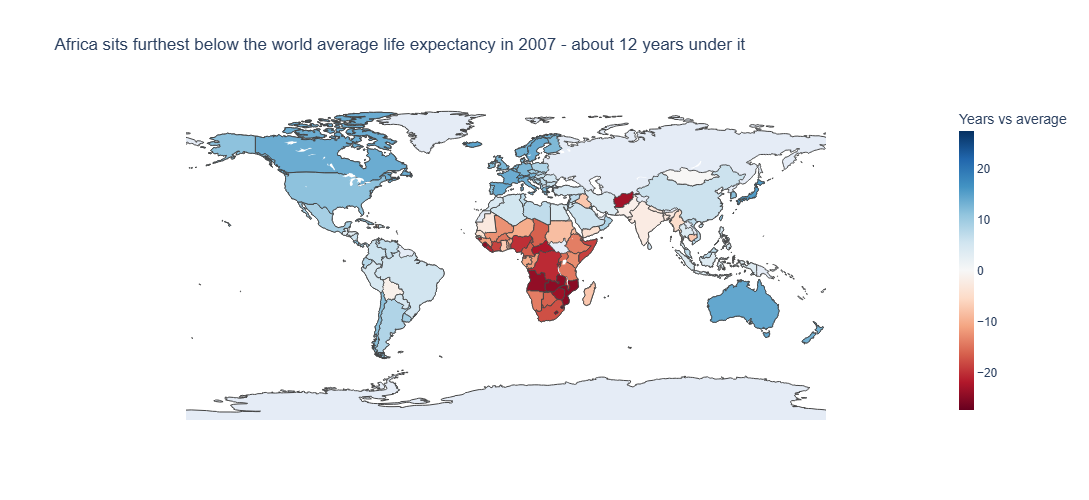

In [2]:
# Task 1
gm = px.data.gapminder()
gm_2007 = gm.loc[gm['year'] == 2007].copy()

world_avg = gm_2007['lifeExp'].mean()
gm_2007['lifeExp_dev'] = gm_2007['lifeExp'] - world_avg   # positive = above average, negative = below

fig = px.choropleth(
    gm_2007,
    locations='iso_alpha',
    locationmode='ISO-3',
    color='lifeExp_dev',
    color_continuous_scale='RdBu',       # diverging: red = below average, blue = above
    color_continuous_midpoint=0,         # white at zero = world average
    hover_name='country',
    hover_data={'lifeExp': ':.1f', 'lifeExp_dev': ':+.1f', 'iso_alpha': False},
    labels={'lifeExp': 'Life expectancy (years)',
            'lifeExp_dev': f'Years vs world avg ({world_avg:.1f})'},
    title='Africa sits furthest below the world average life expectancy in 2007 - about 12 years under it',
    height=500, width=1000
)
fig.update_layout(
    font=dict(family='Arial', size=12),
    geo=dict(showframe=False),
    coloraxis_colorbar=dict(title='Years vs average', thickness=15, len=1),
)
fig.show()


### Task 1 — Design decisions

**Chart type:** `px.choropleth` - Gapminder uses built-in ISO-3 country codes, so no GeoJSON is needed, and a static world projection is enough for a global overview.

**Colour scale:** Diverging (`RdBu`, midpoint 0) - the value is a deviation from the world average (about 67 years), so there are two directions (above/below) with a meaningful neutral centre.

## Task 2 — Find your own GeoJSON

**What to build:** A choropleth using a GeoJSON file you find yourself online.

**Requirements:**
- Find a free GeoJSON file for any geography that interests you (country, region, city)
- Create or find a matching dataset with at least one numeric variable per region
- Build either a `px.choropleth` or `px.choropleth_mapbox` — state your choice and reason in the markdown cell below
- Correctly identify and set `featureidkey` by inspecting the GeoJSON properties
- Choose sequential or diverging scale — state your reason in the markdown cell below
- Insight title naming a geographic finding

**Where to find GeoJSON files:**
- [geojson.xyz](https://geojson.xyz/) — countries, cities, natural features
- [naturalearthdata.com](https://www.naturalearthdata.com/) — global admin boundaries
- [github.com/datasets/geo-countries](https://github.com/datasets/geo-countries) — country polygons
- Search: `[country name] [admin level] GeoJSON github` — most countries have free boundary files on GitHub

> 💡 Before plotting, always inspect your GeoJSON properties first:
> ```python
> print(my_geojson['features'][0]['properties'])
> ```
> The property name that matches your dataframe's location column is what goes in `featureidkey='properties.???'`


### Task 2 — Design decisions

**GeoJSON source:** [isellsoap/deutschlandGeoJSON](https://github.com/isellsoap/deutschlandGeoJSON) - `2_bundeslaender/4_niedrig.geo.json` (Germany's 16 federal states). Properties: `id`, `name`, `type`, so `featureidkey='properties.name'`.

**Data:** 2023 population estimates per federal state (same figures as used in the lecture notes), compared against the average state population.

**Chart type chosen** (`px.choropleth` or `px.choropleth_mapbox`) **and reason:**

`px.choropleth_map` (the current tile-based version of `px.choropleth_mapbox`) - the city-states Berlin, Bremen and Hamburg are tiny on a static map, so zoom/pan on an interactive basemap lets you inspect them.

**Colour scale chosen** (sequential or diverging) **and reason:**

Diverging (`RdBu`, midpoint 0) - the variable is the difference between a state's population and the average state, so there are above/below values around a meaningful neutral point.

{'id': 'DE-BW', 'name': 'Baden-Württemberg', 'type': 'State'}


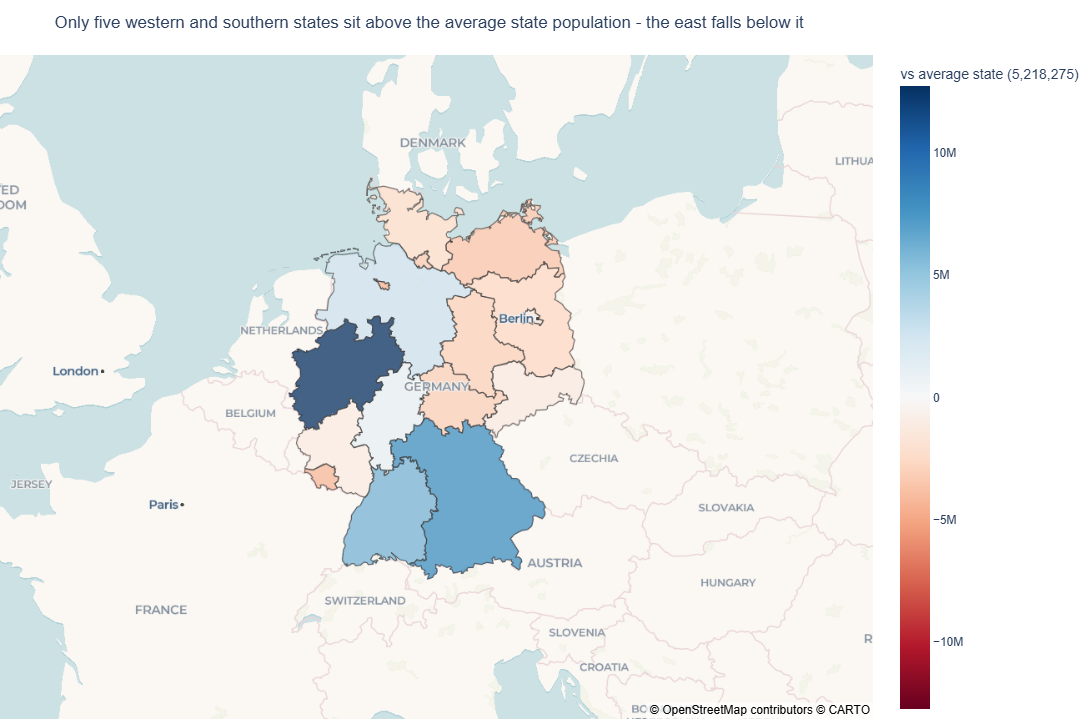

In [3]:
# Task 2
import urllib.request

url = 'https://raw.githubusercontent.com/isellsoap/deutschlandGeoJSON/main/2_bundeslaender/4_niedrig.geo.json'
with urllib.request.urlopen(url) as file:
    my_geojson = json.load(file)

# Inspect the properties to find the right featureidkey
print(my_geojson['features'][0]['properties'])

# Population of Germany's federal states (2023 estimates)
pop = pd.DataFrame({
    'State': ['Baden-Württemberg', 'Bayern', 'Berlin', 'Brandenburg', 'Bremen',
              'Hamburg', 'Hessen', 'Niedersachsen', 'Mecklenburg-Vorpommern',
              'Nordrhein-Westfalen', 'Rheinland-Pfalz', 'Saarland',
              'Sachsen', 'Sachsen-Anhalt', 'Schleswig-Holstein', 'Thüringen'],
    'Population': [11237000, 13223000, 3769000, 2535200, 680300,
                   1858200, 6308900, 7982400, 1610000,
                   17947000, 4104000, 984400,
                   4051000, 2178000, 2906000, 2118000]
})

# Sanity check: every state name matches a GeoJSON feature
geo_names = {f['properties']['name'] for f in my_geojson['features']}
assert set(pop['State']) == geo_names

avg_pop = pop['Population'].mean()
pop['Pop_vs_average'] = pop['Population'] - avg_pop

fig = px.choropleth_map(
    pop,
    geojson=my_geojson,
    locations='State',
    featureidkey='properties.name',
    color='Pop_vs_average',
    color_continuous_scale='RdBu',
    color_continuous_midpoint=0,
    hover_name='State',
    hover_data={'Population': ':,', 'Pop_vs_average': ':+,.0f', 'State': False},
    labels={'Pop_vs_average': f'vs average state ({avg_pop:,.0f})'},
    title='Only five western and southern states sit above the average state population - the east falls below it',
    center={'lat': 51.1657, 'lon': 10.4515},
    zoom=4.5,
    opacity=0.75,
    height=700,
)
fig.update_layout(
    font=dict(family='Arial', size=12),
    margin=dict(l=0, r=0, t=55, b=0),
)
fig.show()
